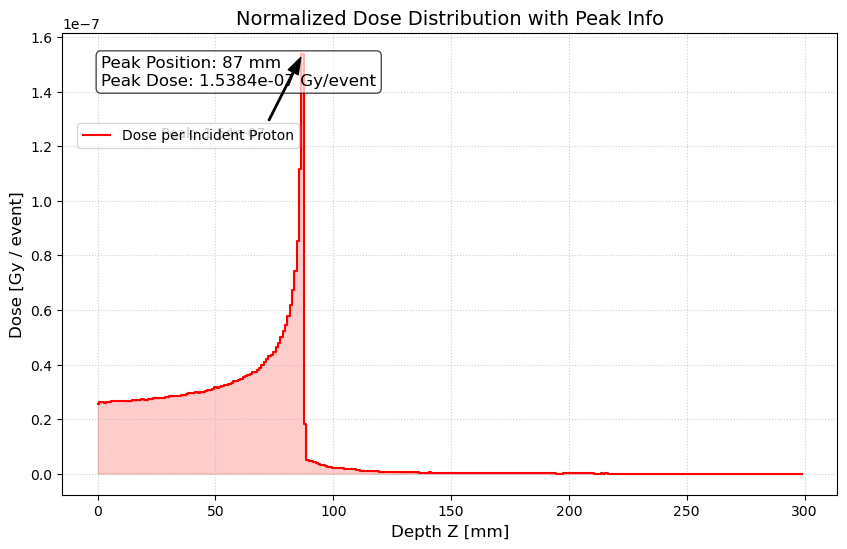

Peak detected at Z=87 mm with dose=1.5384e-07 Gy/event


In [1]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. データの読み込み
df_dose = pd.read_csv("carbonDose.csv", encoding="utf-8", comment='#',  names=['iX', 'iY', 'iZ', 'dose_Gy', 'dose_sq', 'entry'])

# 2. 1粒子あたりの線量に正規化 (beamOn 2000)
num_events = 2000
df_dose['dose_per_event'] = df_dose['dose_Gy'] / num_events

# 3. ピーク情報の取得
max_val = df_dose['dose_per_event'].max()
peak_z = df_dose.loc[df_dose['dose_per_event'].idxmax(), 'iZ']

# 4. グラフの描画
plt.figure(figsize=(10, 6))

# 線量分布のプロット（ステッププロット）
plt.step(df_dose['iZ'], df_dose['dose_per_event'], where='mid', color='red', label='Dose per Incident Proton')
plt.fill_between(df_dose['iZ'], df_dose['dose_per_event'], step='mid', color='red', alpha=0.2)

# 5. ピーク情報の書き込み (テキストボックス)
textstr = '\n'.join((
    f'Peak Position: {peak_z} mm',
    f'Peak Dose: {max_val:.4e} Gy/event'
))
props = dict(boxstyle='round', facecolor='white', alpha=0.7)
plt.text(0.05, 0.95, textstr, transform=plt.gca().transAxes, fontsize=12,
        verticalalignment='top', bbox=props)

# ピーク位置への矢印アノテーション
plt.annotate(f'Peak: {max_val:.2e}', xy=(peak_z, max_val), xytext=(peak_z-60, max_val*0.8),
             arrowprops=dict(facecolor='black', shrink=0.05, width=1, headwidth=8),
             fontsize=10)

# 6. グラフの装飾
plt.xlabel('Depth Z [mm]', fontsize=12)
plt.ylabel('Dose [Gy / event]', fontsize=12)
plt.title('Normalized Dose Distribution with Peak Info', fontsize=14)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(loc='upper left', bbox_to_anchor=(0.01, 0.82))

# 7. 保存
plt.savefig('dose_distribution_with_peak.png', dpi=300, bbox_inches='tight')
plt.show()

print(f"Peak detected at Z={peak_z} mm with dose={max_val:.4e} Gy/event")